# IND320 - Project Work Part 2
**Student:** Sania Minaipour

## Links 
- GitHub repository:
- Streamlit app:

## AI Usage

I used Claude a lot for help with the setup: Docker, Java, Spark, Cassandra and the problems
with my Python environment in OneDrive. It also helped me write the code for the NVE and
ENTSO-E API calls, for writing to and reading from Cassandra with Spark,and for saving data
in MongoDB.

I ran all the code myself and checked the results against the data. I also made choices along
the way, for example selecting areas by both type and number, and changing the flow plot to one
panel per connection when the first version was too hard to read. When something did not work,
I used the error messages to find out why, and I changed the code until it worked.

## Setup:

In [5]:
import os, sys, tomllib

# Java 17 and Hadoop winutils are needed for Spark on Windows
os.environ["JAVA_HOME"] = r"C:\Users\Sania Minaipour\AppData\Local\Programs\Microsoft\jdk-17.0.20.101-hotspot"
os.environ["HADOOP_HOME"] = "C:/Hadoop/hadoop-3.3.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Read tokens/passwords from a local file that is NOT on GitHub
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
print(sys.executable)

c:\venvs\ind320\Scripts\python.exe


## Spark og Cassandra 

In [7]:
from pyspark.sql import SparkSession
from cassandra.cluster import Cluster
from datetime import datetime

# Start Spark WITH the Cassandra connector (first Spark session in this kernel)
spark = (SparkSession.builder.appName("ind320").master("local[*]")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.jars.ivy", "C:/spark_ivy")          # path without spaces
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate())
print(spark.version)

# Create keyspace and table
session = Cluster(["127.0.0.1"], port=9042).connect()
session.execute("""CREATE KEYSPACE IF NOT EXISTS entsoe
    WITH replication = {'class':'SimpleStrategy','replication_factor':1}""")
session.execute("""CREATE TABLE IF NOT EXISTS entsoe.flows (
    from_area text, to_area text, ts timestamp, mw double,
    PRIMARY KEY ((from_area, to_area), ts))""")

# Test: write one row with Spark and read it back
test = spark.createDataFrame([("TEST", "TEST", datetime(2025, 1, 1), 1.0)],
                             ["from_area", "to_area", "ts", "mw"])
(test.write.format("org.apache.spark.sql.cassandra")
    .options(keyspace="entsoe", table="flows").mode("append").save())
(spark.read.format("org.apache.spark.sql.cassandra")
    .options(keyspace="entsoe", table="flows").load().show())

3.5.1
+---------+-------+-------------------+------------------+
|from_area|to_area|                 ts|                mw|
+---------+-------+-------------------+------------------+
|     NO_2|  DE_LU|2024-10-14 20:00:00|           1352.48|
|     NO_2|  DE_LU|2024-10-14 21:00:00|            1271.0|
|     NO_2|  DE_LU|2024-10-14 22:00:00|            1323.6|
|     NO_2|  DE_LU|2024-10-14 23:00:00|            1363.4|
|     NO_2|  DE_LU|2024-10-15 00:00:00|            1375.6|
|     NO_2|  DE_LU|2024-10-15 01:00:00|           1403.48|
|     NO_2|  DE_LU|2024-10-15 02:00:00|           1404.56|
|     NO_2|  DE_LU|2024-10-15 03:00:00|           1403.96|
|     NO_2|  DE_LU|2024-10-15 04:00:00|           1389.96|
|     NO_2|  DE_LU|2024-10-15 05:00:00|            1393.2|
|     NO_2|  DE_LU|2024-10-15 06:00:00|1150.6399999999999|
|     NO_2|  DE_LU|2024-10-15 07:00:00|           1049.28|
|     NO_2|  DE_LU|2024-10-15 08:00:00|           1086.12|
|     NO_2|  DE_LU|2024-10-15 09:00:00|           

## MongoDB

In [8]:
from pymongo import MongoClient
mongo = MongoClient(secrets["mongo"]["uri"])
db = mongo["ind320"]
print(db.list_collection_names())

['ping']


## NVE areas

In [9]:
import requests, pandas as pd

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
HEAD = {"Accept": "application/json"}

areas = requests.get(f"{BASE}/HentOmråder", headers=HEAD, timeout=60).json()
print(type(areas), len(areas))
print(areas[:2])          # shows the real structure

# Flatten whatever structure comes back into one table
def flatten(x, group=None):
    rows = []
    if isinstance(x, dict):
        if "omrnr" in x:                      # an area record
            rows.append({"group": group, **x})
        else:                                 # nested groups
            for k, v in x.items():
                rows += flatten(v, k)
    elif isinstance(x, list):
        for item in x:
            rows += flatten(item, group)
    return rows

areas_df = pd.DataFrame(flatten(areas))
areas_df

<class 'list'> 1
[{'land': [{'navn': 'Norge', 'navn_langt': 'Norge', 'beskrivelse': 'Hele landet', 'omrType': 'NO', 'omrnr': 0}], 'elspot': [{'navn': 'NO 1', 'navn_langt': 'Elspotområde 1', 'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).', 'omrType': 'EL', 'omrnr': 1}, {'navn': 'NO 2', 'navn_langt': 'Elspotområde 2', 'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.', 'omrType': 'EL', 'omrnr': 2}, {'navn': 'NO 3', 'navn_langt': 'Elspotområde 3', 'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.', 'omrType': 'EL', 'omrnr': 3}, {'navn': 'NO 4', 'navn_langt': 'Elspotområde 4', 'beskrivelse': 'Nord-Norge. Omfatter resten av Trøndelag og Nord-Norge.', 'omrType': 'EL', 'omrnr': 4}, {'navn':

,group,navn,navn_langt,beskrivelse,omrType,omrnr
0,land,Norge,Norge,Hele landet,NO,0
1,elspot,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,elspot,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,elspot,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,elspot,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,elspot,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,vassdrag,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,vassdrag,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,vassdrag,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,vassdrag,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


### Areas covered by the NVE API

The NVE Magasinstatistikk API groups its areas in three types:
- **NO** (land): one area, 0 = the whole of Norway.
- **EL** (elspot): five areas, NO 1 to NO 5, which follow the Norwegian electricity
  price areas (from south-east, NO 1, to Nord-Norge, NO 4, and Vest-Norge, NO 5).
- **VASS** (vassdrag): four watercourse areas, from south-east Norway (1) to
  northern Norway (4).

The ENTSO-E API describes Norway with its bidding zones NO_1 to NO_5, which correspond
to the same five price areas, and it adds the connections to neighbouring countries.
Because EL and VASS both use area numbers 1-4, an area must be identified by both type
and number.

## NVE reservoir data

In [10]:
# Download ALL reservoir statistics directly from the API (replaces the CSV file)
r = requests.get(f"{BASE}/HentOffentligData", headers=HEAD, timeout=120)
r.raise_for_status()
df = pd.DataFrame(r.json())

# Same English names as in part 1
df = df.rename(columns={
    "dato_Id": "Date", "omrType": "Area_Type", "omrnr": "Area_Number",
    "iso_aar": "ISO_Year", "iso_uke": "ISO_Week", "fyllingsgrad": "Fill_Percentage",
    "kapasitet_TWh": "Capacity_TWh", "fylling_TWh": "Fill_TWh",
    "neste_Publiseringsdato": "Next_Publication_Date",
    "fyllingsgrad_forrige_uke": "Fill_Percentage_Previous_Week",
    "endring_fyllingsgrad": "Fill_Percentage_Change"})

# Time columns: Date as datetime, sorted; the 0001-01-01 placeholder becomes NaT
df["Date"] = pd.to_datetime(df["Date"])
df["Next_Publication_Date"] = pd.to_datetime(df["Next_Publication_Date"], errors="coerce")
df = df.sort_values(["Area_Type", "Area_Number", "Date"]).reset_index(drop=True)

print(df.shape)
print(df.groupby(["Area_Type", "Area_Number"]).size())

(14922, 11)
Area_Type  Area_Number
EL         1              1658
           2              1658
           3              1658
           4              1658
           5              1658
NO         0              1658
VASS       1              1658
           2              1658
           3              1658
dtype: int64


## Plot each column separately

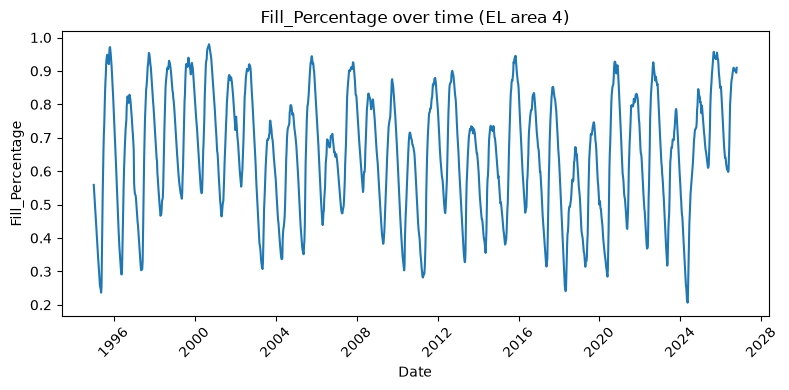

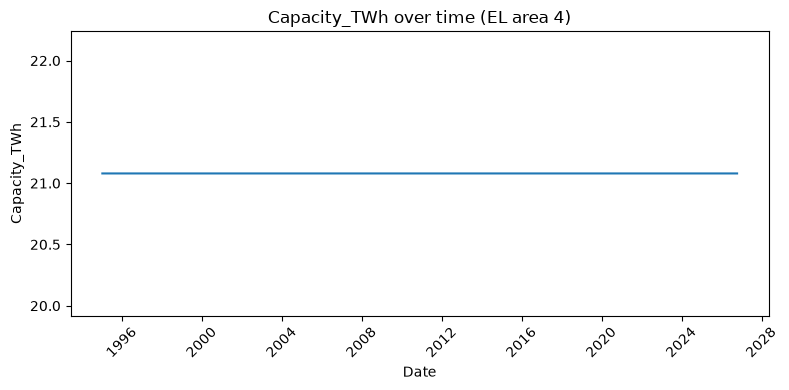

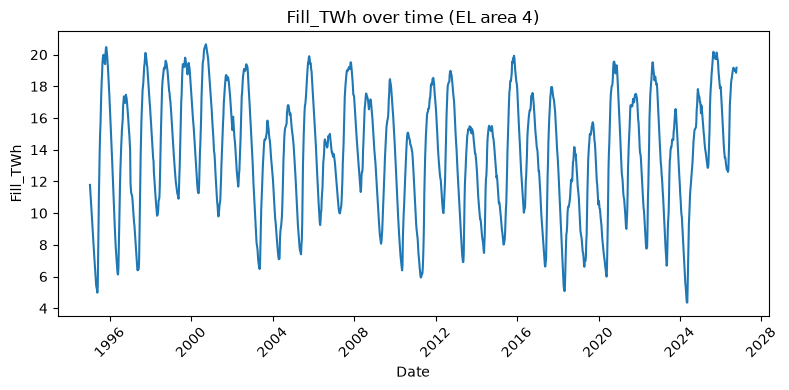

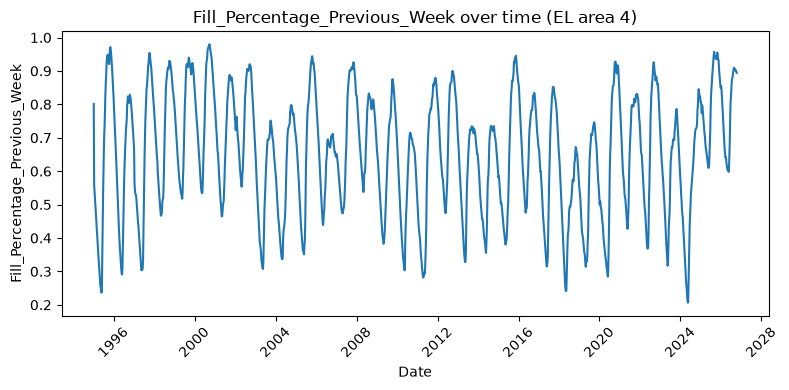

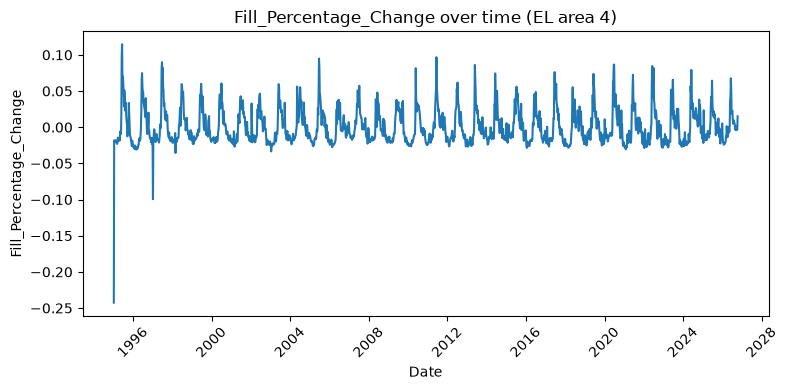

In [11]:
import matplotlib.pyplot as plt
#Filter to a single area(area 4) for clean time series plotting (data has multiple areas per date)
area_df = df[(df["Area_Type"] == "EL") & (df["Area_Number"] == 4)].sort_values("Date")


# List of numeric columns to plot
numeric_cols = ["Fill_Percentage", "Capacity_TWh", "Fill_TWh", 
                 "Fill_Percentage_Previous_Week", "Fill_Percentage_Change"]

# Plot each numeric column separately over time
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.plot(area_df["Date"], area_df[col])
    plt.title(f"{col} over time (EL area 4)")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Plot all columns together

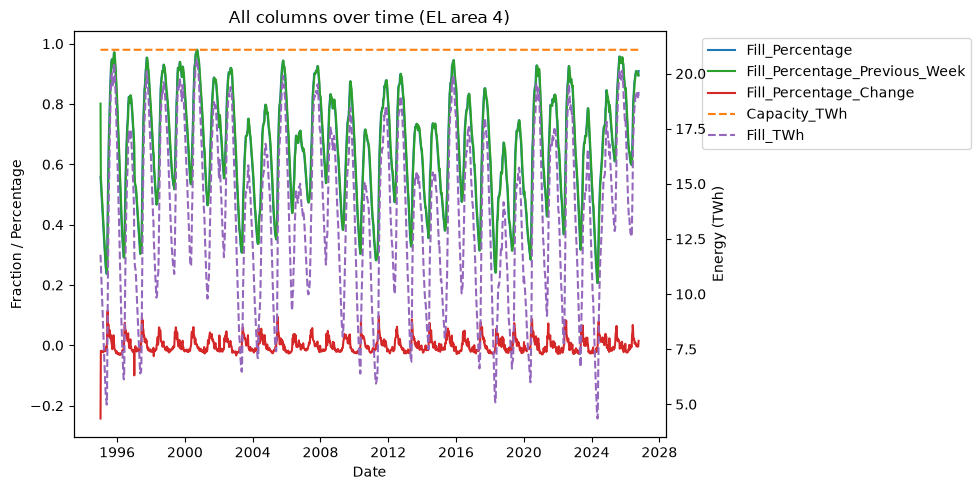

In [ ]:
#Since columns have different units/scales (percentages vs. TWh values), use two y-axes (twin axes) instead of normalizing: percentage-based columns 
#on the left axis, TWh-based columns on the right axis. This shows the actual 
#values in their original units, instead of artificially rescaling everything to 0-1.

percentage_cols = ["Fill_Percentage", "Fill_Percentage_Previous_Week", "Fill_Percentage_Change"]
twh_cols = ["Capacity_TWh", "Fill_TWh"]

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

colors_pct = ["tab:blue", "tab:green", "tab:red"]
colors_twh = ["tab:orange", "tab:purple"]

# Plot percentage-based columns on the left axis
lines = []
for col, color in zip(percentage_cols, colors_pct):
    line, = ax1.plot(area_df["Date"], area_df[col], label=col, color=color)
    lines.append(line)

# Plot TWh-based columns on the right axis
for col, color in zip(twh_cols, colors_twh):
    line, = ax2.plot(area_df["Date"], area_df[col], label=col, color=color, linestyle="--")
    lines.append(line)

# Labels and title
ax1.set_xlabel("Date")
ax1.set_ylabel("Fraction / Percentage")
ax2.set_ylabel("Energy (TWh)")
ax1.set_title(f"All columns over time (EL area 4)")

# Combine legends from both axes into a single legend
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", bbox_to_anchor=(1.05, 1))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## ENTSO-E cross border flows

In [13]:
from entsoe import EntsoePandasClient
client = EntsoePandasClient(api_key=secrets["entsoe"]["token"])
s = client.query_crossborder_flows("NO_2", "NL",
        start=pd.Timestamp("2025-01-01", tz="Europe/Brussels"),
        end=pd.Timestamp("2025-01-08", tz="Europe/Brussels"))
print(len(s)); print(s.head())

672
2025-01-01 00:00:00+01:00    0.0
2025-01-01 00:15:00+01:00    0.0
2025-01-01 00:30:00+01:00    0.0
2025-01-01 00:45:00+01:00    0.0
2025-01-01 01:00:00+01:00    0.0
Freq: 15min, dtype: float64


In [ ]:
# Same week in the opposite direction (NL -> NO_2). ENTSO-E reports each direction as its
# own series, so one direction is often 0 when the power flows the other way.
s_rev = client.query_crossborder_flows("NL", "NO_2",
        start=pd.Timestamp("2025-01-01", tz="Europe/Brussels"),
        end=pd.Timestamp("2025-01-08", tz="Europe/Brussels"))
print(s_rev.describe())

count    672.000000
mean      58.118690
std      172.547028
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      649.090000
dtype: float64


## ENTSO-E dowload, two years

In [15]:
import pandas as pd
from entsoe import EntsoePandasClient

client = EntsoePandasClient(api_key=secrets["entsoe"]["token"])

# Last two years
end = pd.Timestamp.now(tz="Europe/Brussels").normalize() - pd.Timedelta(days=1)
start = end - pd.DateOffset(years=2)

# Connections to Norway (area codes as used by entsoe-py)
pairs = [("NO_2", "NL"), ("NO_2", "DE_LU"), ("NO_2", "DK_1"), ("NO_1", "SE_3")]

frames, failed = [], []
for a, b in pairs:
    for src, dst in [(a, b), (b, a)]:               # both directions
        try:
            s = client.query_crossborder_flows(src, dst, start=start, end=end)
            f = s.resample("h").mean().rename("mw").reset_index()   # 15 min -> hourly mean
            f.columns = ["ts", "mw"]
            f["ts"] = f["ts"].dt.tz_convert("UTC").dt.tz_localize(None)
            f["from_area"], f["to_area"] = src, dst
            frames.append(f)
            pd.concat(frames, ignore_index=True).to_csv("flows_cache.csv", index=False)  # save as we go
            print("OK    ", src, "->", dst, len(f))
        except Exception as e:
            failed.append((src, dst, str(e)[:80]))
            print("FAILED", src, "->", dst, str(e)[:80])

flows = pd.concat(frames, ignore_index=True)
print(flows.groupby(["from_area", "to_area"]).size())

OK     NO_2 -> NL 17520
OK     NL -> NO_2 17520
OK     NO_2 -> DE_LU 17520
OK     DE_LU -> NO_2 17520
OK     NO_2 -> DK_1 17520
OK     DK_1 -> NO_2 17520
OK     NO_1 -> SE_3 17520
OK     SE_3 -> NO_1 17520
from_area  to_area
DE_LU      NO_2       17520
DK_1       NO_2       17520
NL         NO_2       17520
NO_1       SE_3       17520
NO_2       DE_LU      17520
           DK_1       17520
           NL         17520
SE_3       NO_1       17520
dtype: int64


## Cassandra via Sparks

In [16]:
# Plain Python rows avoid pandas/PySpark version problems
rows = [(r.from_area, r.to_area, r.ts.to_pydatetime(), float(r.mw))
        for r in flows.dropna().itertuples()]
sdf = spark.createDataFrame(rows, ["from_area", "to_area", "ts", "mw"])

(sdf.write.format("org.apache.spark.sql.cassandra")
    .options(keyspace="entsoe", table="flows").mode("append").save())

# Extract the relevant columns with Spark
back = (spark.read.format("org.apache.spark.sql.cassandra")
        .options(keyspace="entsoe", table="flows").load())
selected = back.select("from_area", "to_area", "ts", "mw").filter("from_area != 'TEST'")
print(selected.count())

pdf = pd.DataFrame([r.asDict() for r in selected.collect()])
pdf["ts"] = pd.to_datetime(pdf["ts"])

140720


In [21]:
print(len(pdf))
print(pdf.groupby(["from_area", "to_area"]).size())

140720
from_area  to_area
DE_LU      NO_2       17590
DK_1       NO_2       17590
NL         NO_2       17590
NO_1       SE_3       17590
NO_2       DE_LU      17590
           DK_1       17590
           NL         17590
SE_3       NO_1       17590
dtype: int64


## Plots 

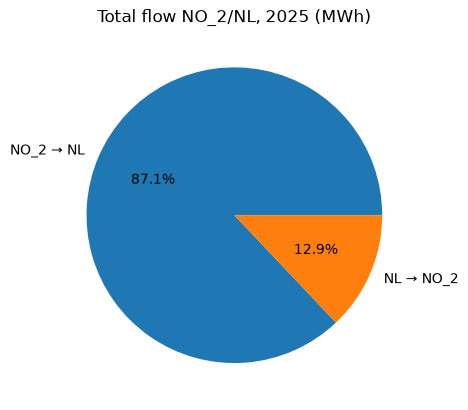

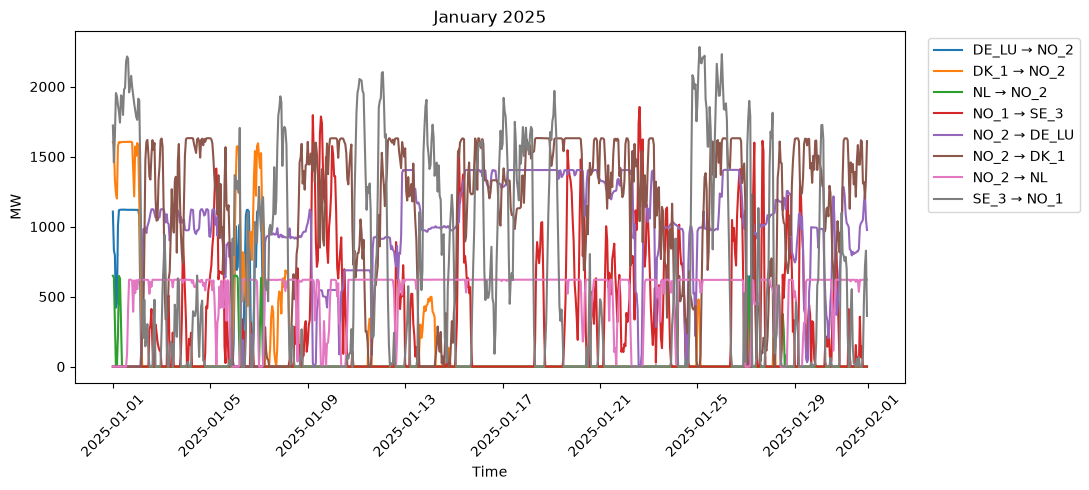

In [17]:

pdf["year"], pdf["month"] = pdf["ts"].dt.year, pdf["ts"].dt.month
a, b, year = "NO_2", "NL", 2025        # chosen connection and year

# Pie chart: total energy out of and into Norway for one connection and year
out_ = pdf[(pdf.from_area == a) & (pdf.to_area == b) & (pdf.year == year)]["mw"].sum()
in_  = pdf[(pdf.from_area == b) & (pdf.to_area == a) & (pdf.year == year)]["mw"].sum()
plt.pie([out_, in_], labels=[f"{a} → {b}", f"{b} → {a}"], autopct="%1.1f%%")
plt.title(f"Total flow {a}/{b}, {year} (MWh)")
plt.show()

# Line plot: first month of the year, one line per connection and direction
m = pdf[(pdf.year == year) & (pdf.month == 1)]
fig, ax = plt.subplots(figsize=(11, 5))
for (f, t), g in m.groupby(["from_area", "to_area"]):
    ax.plot(g["ts"], g["mw"], label=f"{f} → {t}")
ax.set_xlabel("Time"); ax.set_ylabel("MW"); ax.set_title(f"January {year}")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Insert into MongoDB

In [18]:
# Insert the Spark-extracted data into MongoDB, in chunks
records = [{"from_area": r.from_area, "to_area": r.to_area,
            "ts": r.ts.to_pydatetime(), "mw": float(r.mw)} for r in pdf.itertuples()]
col = db["crossborder_flows"]
col.delete_many({})
for i in range(0, len(records), 20000):
    col.insert_many(records[i:i + 20000])
print(col.count_documents({}))

140720


## Log

In part 2 I stopped using the CSV file and used real APIs and databases instead: the NVE
reservoir API, the ENTSO-E API, Cassandra with Spark, and MongoDB. Making all the tools work
took much longer than I expected.

Spark and Cassandra on Windows was the hardest part. I needed Docker, Java 17, the Hadoop
winutils files and a Cassandra connector that matched Spark 3.5.1. At the same time my
Python environment broke. The project is in OneDrive, and OneDrive made some of the package
files unreadable, so nothing would import. I had to make a new environment outside OneDrive
before it worked again.

The NVE API was easier than I thought. The data endpoint has no parameters for dates or
areas, so I just download everything in one call. The area list has three types: NO (the
whole country), EL (the five price areas) and VASS (watercourse areas). The list says
VASS 1-4, but the data I could find only has VASS 1-3. EL and VASS use some of the same
area numbers, so now I choose an area with both type and number. In part 1 I only used the
number, and that happened to give me the EL 4 series. For the time columns I did the same
as in part 1: sort by date, make the date a datetime, and treat the 0001-01-01 date as
missing.

The ENTSO-E data comes every 15 minutes, and each direction of a connection is its own
series. This means one direction is often zero when the power goes the other way. I took
the average per hour and only used four connections. Then I put about 140,000 hourly values
into Cassandra with Spark, took them out again with Spark, and saved them in MongoDB. The
app reads from MongoDB.

In Streamlit the slider cannot decide what the NVE API sends, because the API has no date
parameters. So the data is downloaded once and cached, and the slider only picks which
months I use. My first line plot of the cross-border flows was impossible to read, with
eight lines in the same plot. I changed it to one small plot for each connection, with one
line for each direction, and then it was much better.

What I learned is to test each part on its own before putting everything together. When
something failed, it was almost always the setup and not my code.